# Lab 3 — Millions of TVs: Who Is Actually Watching?

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
TABLE_NAMES = ["programs", "viewings", "daily_weights", "viewer_attributes",
               "attributes", "acr_sessions", "hh_attributes", "reference_ratings"]
(programs, viewings, daily_weights, viewer_attributes,
 attributes, acr_sessions, hh_attributes, reference_ratings) = (
    pd.read_parquet(f"{DATA_DIR}/{name}.parquet") for name in TABLE_NAMES)

In [2]:
STUDY_DAYS = pd.date_range("2024-10-14", "2024-10-27")
NETWORKS = sorted(programs["network_code"].unique())
MAJOR_FIVE = ["CBS", "NBC", "ABC", "FOX", "FNC"]
MIN_SESSION_HOURS = 1 / 60                     
DAY_START_OFFSET = pd.Timedelta(hours=6)        


def to_eastern(values, from_utc=False):
    ts = pd.to_datetime(values, utc=from_utc)
    if ts.dt.tz is None:
        return ts
    return ts.dt.tz_convert("America/New_York").dt.tz_localize(None)


def broadcast_day(ts):
    return (ts - DAY_START_OFFSET).dt.normalize()


def span_hours(start, end):
    return (end - start).dt.total_seconds() / 3600


def viewers_per_telecast(telecasts, sessions, id_col, min_seconds=60):
    """(telecast_id, id_col) pairs where the viewer spent >= min_seconds on the telecast's network."""
    air = telecasts[["telecast_id", "network_code", "start_ts", "end_ts"]].rename(
        columns={"start_ts": "air_start", "end_ts": "air_end"})
    pairs = sessions[["network_code", id_col, "start_ts", "end_ts"]].merge(air, on="network_code")
    pairs = pairs[(pairs["start_ts"] < pairs["air_end"]) & (pairs["end_ts"] > pairs["air_start"])]
    overlap_start = pairs[["start_ts", "air_start"]].max(axis=1)
    overlap_end = pairs[["end_ts", "air_end"]].min(axis=1)
    seconds = (overlap_end - overlap_start).dt.total_seconds()
    seconds = seconds.groupby([pairs["telecast_id"], pairs[id_col]]).sum()
    return seconds[seconds >= min_seconds].reset_index()[["telecast_id", id_col]]


def income_bucket(band):
    if pd.isna(band):
        return None
    if band.startswith(("Under", "$25")):
        return "Under $50k"
    if band.startswith(("$50", "$75")):
        return "$50-100k"
    return "$100k+"


AGE_LIMITS = [(35, "18-34"), (50, "35-49"), (65, "50-64")]


def age_bucket(age_value):
    if pd.isna(age_value):
        return None
    for limit, label in AGE_LIMITS:
        if age_value < limit:
            return label
    return "65+"


for table in (programs, viewings):
    for col in ("start_ts", "end_ts"):
        table[col] = to_eastern(table[col])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"]).dt.normalize()
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).dt.normalize()
viewings["bcast_day"] = broadcast_day(viewings["start_ts"])
viewings["hours"] = span_hours(viewings["start_ts"], viewings["end_ts"])

weights_in_window = daily_weights[daily_weights["broadcast_date"].isin(STUDY_DAYS)]
hh_daily_w = weights_in_window[weights_in_window["resp_type"] == "H"]
hh_mean_weight = hh_daily_w.groupby("respondent_id")["weight"].mean()
hh_views = viewings[(viewings["resp_type"] == "H") & viewings["bcast_day"].isin(STUDY_DAYS)]


tv_sessions = acr_sessions.copy()
tv_sessions["network_code"] = tv_sessions["network_code"].mask(tv_sessions["network_code"] == "")
tv_sessions["start_ts"] = to_eastern(tv_sessions["start_utc"], from_utc=True)
tv_sessions["end_ts"] = to_eastern(tv_sessions["end_utc"], from_utc=True)
tv_sessions["bcast_day"] = broadcast_day(tv_sessions["start_ts"])
tv_sessions = tv_sessions[tv_sessions["bcast_day"].isin(STUDY_DAYS)].copy()
tv_sessions["hours"] = span_hours(tv_sessions["start_ts"], tv_sessions["end_ts"])

valid = tv_sessions[tv_sessions["hours"] >= MIN_SESSION_HOURS]
live_tv = valid[(valid["session_type"] == "live") & valid["network_code"].notna()]
tvs_per_day = valid.groupby("bcast_day")["tv_id"].nunique()


joined_attrs = viewer_attributes.merge(attributes, on="attr_id")


def wide_attrs(frame):
    return frame.pivot_table(index="respondent_id", columns="attr_group",
                             values="attr_name", aggfunc="first")


is_household = joined_attrs["respondent_id"] % 100 == 0
hh_profile = wide_attrs(joined_attrs[is_household])
person_profile = wide_attrs(joined_attrs[~is_household])

age_rows = viewer_attributes.loc[viewer_attributes["attr_id"] == 300].drop_duplicates("respondent_id")
person_age = pd.to_numeric(age_rows.set_index("respondent_id")["value"])

## Task 1.1 — Five questions

**Answer:**

| Question | `acr_sessions` (smart-TV feed) | Lab 1 `viewings` (panel) |
|---|---|---|
| **Grain** | A session is an uninterrupted stretch of one thing playing on one smart TV; it closes when the network, the program or the input changes. | A single viewing event by one person, or by one household's TV set, on one network. |
| **Key** | `session_id` (effectively `tv_id` + `start_utc`); a TV is tied to a home only through `hashed_ip`. | `viewing_id` (effectively `respondent_id` + `start_ts`); the household is `respondent_id // 100`. |
| **Coverage** | About 30,000 opted-in smart TVs of one manufacturer, one set per home; any network, apps and unidentified "TV on" time; Oct 14–27, 2024. | About 4,000 recruited households, with every set and every person in the home (guests included); only ten networks; October 2024. |
| **Weight** | None: each TV counts once, so the figures describe the footprint itself and cannot be read as the US. | A daily weight for each household / person that projects to 125.8 M TV homes and 317.3 M people. |
| **Provenance** | Automatic content recognition: screen fingerprints are compared with a library of live feeds and sold by a data vendor; demographics arrive only by matching the IP to a compiled consumer file. | A measurement panel: homes recruited to mirror the US, people meters with log-in, demographics supplied by the panelists themselves. |

**Biggest difference: weight (and the coverage that sits behind it).** The panel is small, but it is built and weighted to represent the US. The smart-TV feed is huge, yet unweighted and self-selected (it only contains people who bought this brand and opted in), so its raw counts cannot be scaled up to the country.

## Task 1.2 — Size and shape

In [3]:
tv_days = tvs_per_day.sum()
summary = {
    "TVs": tv_sessions["tv_id"].nunique(),
    "Sessions": len(tv_sessions),
    "Broadcast days": tv_sessions["bcast_day"].nunique(),
    "Average TVs in-tab per day": round(tvs_per_day.mean(), 1),
    "Hours per TV per day, raw": round(tv_sessions["hours"].sum() / tv_days, 2),
    "Hours per TV per day, after edit rule": round(valid["hours"].sum() / tv_days, 2),
    "Share of sessions dropped": round(1 - len(valid) / len(tv_sessions), 3),
}
for label, value in summary.items():
    print(f"{label}: {value}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [4]:
def hours_share(column):
    totals = valid.groupby(column)["hours"].sum()
    return (totals / valid["hours"].sum()).rename("share of hours")


type_share = hours_share("session_type")
input_share = hours_share("input_source")
display(type_share.sort_values(ascending=False).round(3).to_frame())
display(input_share.sort_values(ascending=False).round(3).to_frame())
print("Share of TV-on hours unknown (%):", round(100 * type_share.get("unknown", 0), 1))

,share of hours
session_type,
unknown,0.396
live,0.322
app,0.257
dvr,0.025


,share of hours
input_source,
built_in_app,0.307
cable_box,0.276
streaming_device,0.231
antenna,0.086
satellite_box,0.076
game_or_disc,0.024


Share of TV-on hours unknown (%): 39.6


**Answer:** in this feed `unknown` makes up 39.6% of TV-on hours. That is the largest single type, ahead of identified live viewing (32.2%), but it is still far below the 66% seen in LG's real October 2025 sample. A real feed would show even more, because the fingerprint library covers only live linear feeds, so anything else on the screen cannot be matched. Real TVs also spend more time on external devices; real viewing is scattered over thousands of local stations and niche channels that the library may lack; and matching breaks down on menus, overlays, picture-in-picture and screensavers. Two examples of viewing that ends up as `unknown`: **streaming via an external box** (Roku, Fire TV or Apple TV over HDMI — `streaming_device` accounts for 23.1% of hours here) and **games or discs** played on a console or Blu-ray player (`game_or_disc`). On-demand and old DVR content that is absent from the live-feed library falls into the same bucket.

## Task 2.1 — Match

In [5]:
homes_per_ip = (hh_attributes.dropna(subset=["hashed_ip"])
                .groupby("hashed_ip")["household_id"].nunique())
tv_table = tv_sessions.groupby("tv_id")["hashed_ip"].first().to_frame()
tv_table["n_hh"] = tv_table["hashed_ip"].map(homes_per_ip).fillna(0)

outcomes = {
    "Matched to one household (%)": tv_table["n_hh"] == 1,
    "Shared IP, unresolved (%)": tv_table["n_hh"] > 1,
    "Not matched (%)": tv_table["n_hh"] == 0,
}
for label, mask in outcomes.items():
    print(label, round(100 * mask.mean(), 1))

Matched to one household (%) 65.2
Shared IP, unresolved (%) 11.8
Not matched (%) 22.9


**Answer:** an IP address points to a network connection, not to a household. Providers reassign dynamic addresses, so the IP recorded in the consumer file may now belong to somebody else. A single IP can also sit in front of many homes (apartment blocks, dorms, carrier-grade NAT) — precisely the "shared" group that cannot be resolved — while one home can appear under several IPs (VPN, phone hotspot, moving house). Hashing conceals the address but leaves all of these problems in place. The key therefore produces both missed and wrong matches, and the homes that do match are not a random subset of the TVs.

## Task 2.2 — Profile

In [6]:
single_ip_homes = hh_attributes[hh_attributes["hashed_ip"].map(homes_per_ip) == 1]
matched_tvs = (tv_table[tv_table["n_hh"] == 1].reset_index()
               .merge(single_ip_homes, on="hashed_ip"))
matched_tvs["income_group"] = matched_tvs["income_band"].map(income_bucket)

panel_hh = hh_profile.join(hh_mean_weight.rename("w"), how="inner")
panel_hh["income_group"] = panel_hh["Household income"].map(income_bucket)
head_ids = person_profile.index[person_profile["Household role"] == "Head of house"]
head_age = pd.Series(person_age.reindex(head_ids).values,
                     index=head_ids // 100 * 100).groupby(level=0).first()
panel_hh["head_age_band"] = head_age.reindex(panel_hh.index).map(age_bucket)

DIMENSIONS = [("region", "Census region"),
              ("income_group", "income_group"),
              ("head_age_band", "head_age_band")]


def compare_dimension(footprint_col, panel_col):
    return pd.DataFrame({
        "footprint share": matched_tvs[footprint_col].value_counts(normalize=True),
        "panel share": panel_hh.groupby(panel_col)["w"].sum() / panel_hh["w"].sum(),
    })


profile = pd.concat([compare_dimension(f, p) for f, p in DIMENSIONS]).dropna()
profile.index.name = "group"
profile["index"] = profile["footprint share"] / profile["panel share"] * 100
display(profile.round({"footprint share": 3, "panel share": 3, "index": 1}))
print("Over-represented (index > 110):", list(profile.index[profile["index"] > 110]))
print("Under-represented (index < 90):", list(profile.index[profile["index"] < 90]))

,footprint share,panel share,index
group,,,
Midwest,0.201,0.210,96.0
Northeast,0.150,0.170,88.0
South,0.383,0.379,101.0
West,0.266,0.241,110.4
$100k+,0.421,0.350,120.1
$50-100k,0.320,0.289,110.8
Under $50k,0.259,0.361,71.8
18-34,0.196,0.190,103.6
35-49,0.348,0.303,115.0


Over-represented (index > 110): ['West', '$100k+', '$50-100k', '35-49']
Under-represented (index < 90): ['Northeast', 'Under $50k', '65+']


**Answer:** the groups above the 110 line are **$100k+ homes (120)**, $50–100k homes (111), households with a head aged **35–49 (115)** and the **West (110)**; heads aged 50–64 also sit slightly above 100 (110). Below 90 are **homes under $50k (72)**, **heads aged 65+ (72)** and the **Northeast (88)**. The South, the Midwest and 18–34 heads are near 100. In short, the footprint is skewed toward middle-aged, middle- and high-income homes and under-covers older and poorer ones. A likely reason is that an opted-in smart-TV footprint is built from homes that recently bought a connected TV, put it online and accepted the data-sharing terms — typical of working-age, better-off, tech-comfortable households — whereas older and lower-income homes tend to keep older sets, leave them offline or decline. A large sample with the wrong mix is still a biased sample.

## Task 2.3 — Ratings

In [ ]:
ref = reference_ratings.merge(programs, on="telecast_id")
watching = viewers_per_telecast(ref, live_tv, "tv_id").groupby("telecast_id").size()
ref["feed_rating"] = ref["telecast_id"].map(watching).fillna(0) / ref["broadcast_date"].map(tvs_per_day) * 100
ref["feed_to_ref"] = ref["feed_rating"] / ref["hh_rating"]

ratings = ref[["program_name", "network_code", "broadcast_date", "feed_rating", "hh_rating", "feed_to_ref"]]
display(ratings.sort_values("feed_to_ref").round({"feed_rating": 1, "hh_rating": 1, "feed_to_ref": 2}))

distance = np.maximum(ratings["feed_to_ref"], 1 / ratings["feed_to_ref"])   
print("Furthest off:", ratings.loc[distance.idxmax(), "program_name"])
print("Closest:", ratings.loc[distance.idxmin(), "program_name"])

,program_name,network_code,broadcast_date,feed_rating,hh_rating,feed_to_ref
3,Hannity,FNC,2024-10-16,0.8,2.3,0.36
2,NCIS,CBS,2024-10-14,5.4,10.6,0.51
4,Unsellable Houses,HGTV,2024-10-16,2.1,3.7,0.57
7,The Real Housewives of New York City,BRAVO,2024-10-15,0.7,1.2,0.60
5,Halloween Baking Championship,FOOD,2024-10-14,1.0,1.6,0.60
0,MLB Postseason,FOX,2024-10-25,16.5,25.9,0.64
6,Grotesquerie,FX,2024-10-16,2.3,3.5,0.64
1,NFL Football,NBC,2024-10-27,21.2,33.1,0.64


Furthest off: Hannity
Closest: NFL Football


**Answer:** the feed's ratings are **too low for all eight telecasts**, with ratios between 0.36 and 0.64. Part of this shortfall is shared by every program: the reference counts viewing on any set in the home, while the feed sees one TV per home (Task 3.1). This is why the telecasts are best compared with one another. **Furthest off: Hannity (0.36)** on Fox News, followed by **NCIS (0.51)** on CBS — the two programs with the oldest audiences. **Closest: Sunday Night Football, the World Series game and Grotesquerie (all 0.64)** — big live sports with broad appeal plus a younger-skewing FX drama. HGTV, Bravo and Food Network land in the middle (0.57–0.60); their ratings are small (1.2–3.7), so their ratios are also less stable. This matches the profile from Task 2.2: the footprint has too few homes with a 65+ head (index 72) and too few homes under $50k (72), and exactly those homes watch cable news and CBS dramas, so those ratings lose the most. A single correction factor cannot repair this, because the error depends on who the audience is.

## Task 3.1 — Hours per home

In [8]:
live_ten = live_tv[live_tv["network_code"].isin(NETWORKS)]
feed_hours = live_ten["hours"].sum() / tvs_per_day.sum()
panel_hours = (hh_views["hours"] * hh_views["weight"]).sum() / hh_daily_w["weight"].sum()
print("Live hours per TV per day (ten networks):", round(feed_hours, 2))
print("Live hours per panel household per day (ten networks):", round(panel_hours, 2))
print("TVs / panel:", round(feed_hours / panel_hours, 3))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
TVs / panel: 0.452


**Answer:** the smart-TV figure is lower: **0.87 live hours per TV per day versus 1.92 per panel household**, which is under half (0.45). The panel meters every set in the home, whereas the feed sees only one TV per home. A typical home has roughly 2.6 sets and only about 1.1 of them are of this brand, so viewing on the bedroom or kitchen TV never gets to the feed. A smaller part of the gap comes from the footprint itself, which has fewer 65+ homes — the heaviest TV viewers. In addition, a smart TV spends a large share of its time on apps and unrecognised sources instead of the ten networks.

## Task 3.2 — Network shares

In [9]:
panel_hours_w = hh_views["hours"] * hh_views["weight"]
net_shares = pd.DataFrame({
    "share in TVs": live_ten.groupby("network_code")["hours"].sum() / live_ten["hours"].sum(),
    "share in panel": panel_hours_w.groupby(hh_views["network_code"]).sum() / panel_hours_w.sum(),
})
net_shares["TVs / panel"] = net_shares["share in TVs"] / net_shares["share in panel"]
display(net_shares.sort_values("share in panel", ascending=False).round(3))

,share in TVs,share in panel,TVs / panel
network_code,,,
NBC,0.214,0.206,1.036
CBS,0.182,0.196,0.928
FOX,0.201,0.194,1.039
ABC,0.196,0.187,1.048
FNC,0.085,0.110,0.774
HGTV,0.034,0.031,1.104
FOOD,0.024,0.022,1.089
FX,0.028,0.022,1.291
HIST,0.019,0.019,1.036


**Answer:** the smart-TV data **understates Fox News (0.77)** and, to a lesser degree, **CBS (0.93)** — the networks with the oldest viewers. It **overstates FX (1.29), Bravo (1.22), HGTV (1.10) and Food Network (1.09)**, which are the younger cable networks. NBC, FOX, ABC and History are close to the panel (1.04–1.05). The pattern repeats what the ratings showed in Task 2.3: the footprint has too few older homes.

## Task 3.3 — What each can see

**Answer:**

*Visible to the panel, invisible to the smart-TV data:*
- **People**: who in the home is watching (age, sex, guests), which makes person ratings such as A25–54 possible; the feed only knows a TV and a modeled household.
- **Every set in the home**, whatever the brand, including old non-smart TVs, and homes that have no connected smart TV at all.
- **A representative, weighted US**, including the older and lower-income homes the footprint misses, which allows projection to 125.8 M households.

*Visible to the smart-TV data, invisible to the panel's ten-network files:*
- **All the other networks** (any US network, not just the ten), together with streaming apps and inputs (`app`, `streaming_device`, `game_or_disc`) — the entire screen time.
- **Fine-grained detail at scale**: about 30,000 homes are enough for small programs, single markets (`dma_code`) and narrow segments.
- **Unrecognised "TV on" time and the input in use** (cable box, antenna, streaming device), showing how the TV is really used.

## Task 4.1 — Daily plots

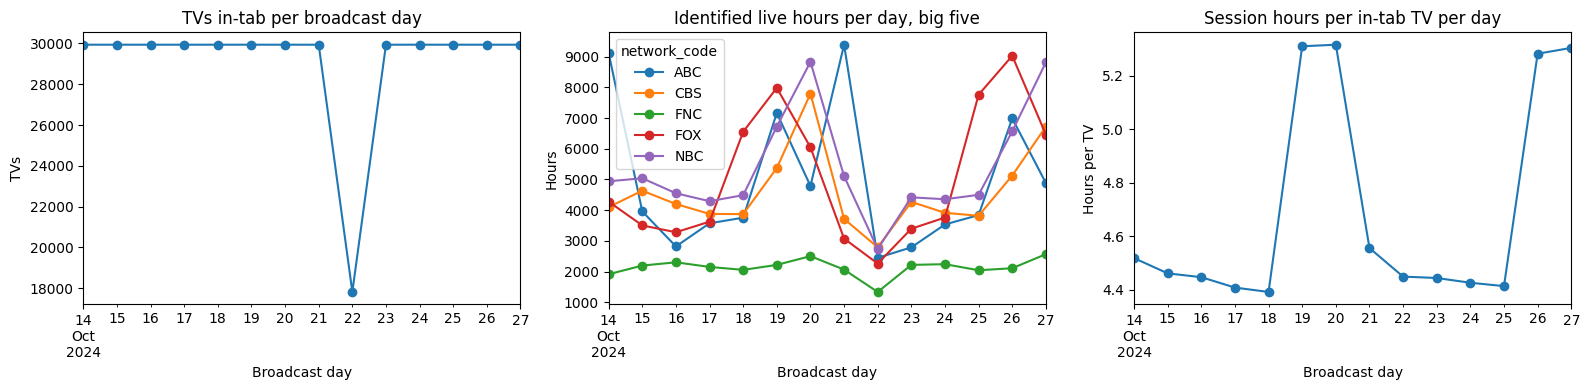

In [10]:
big5_daily = (live_tv[live_tv["network_code"].isin(MAJOR_FIVE)]
              .pivot_table(index="bcast_day", columns="network_code", values="hours", aggfunc="sum"))
hours_per_active_tv = valid.groupby("bcast_day")["hours"].sum() / tvs_per_day

panels = [
    (tvs_per_day, "TVs in-tab per broadcast day", "TVs"),
    (big5_daily, "Identified live hours per day, big five", "Hours"),
    (hours_per_active_tv, "Session hours per in-tab TV per day", "Hours per TV"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, (series, title, ylabel) in zip(axes, panels):
    series.plot(ax=axis, marker="o", title=title)
    axis.set_ylabel(ylabel)
    axis.set_xlabel("Broadcast day")
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [11]:
spike_network = big5_daily.max().idxmax()
spike_date = big5_daily[spike_network].idxmax()
print("Biggest spike (date, network):", spike_date.strftime("%Y-%m-%d"), spike_network)
schedule = programs[(programs["network_code"] == spike_network)
                    & (programs["broadcast_date"] == spike_date)]
display(schedule[["program_name", "episode_name", "start_ts", "duration_min", "is_live"]])

daily_stats = pd.DataFrame({"TVs in-tab": tvs_per_day, "hours per in-tab TV": hours_per_active_tv})
relative_gap = (daily_stats / daily_stats.median() - 1).abs().max(axis=1)   # distance from the typical day
broken_day = relative_gap.idxmax()
print("Broken day (date):", broken_day.strftime("%Y-%m-%d"))
display(daily_stats.round(2))

Biggest spike (date, network): 2024-10-21 ABC


,program_name,episode_name,start_ts,duration_min,is_live
272,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",2024-10-21 07:00:00,120,True
273,Local / Syndicated Programming,NaN,2024-10-21 09:00:00,120,False
274,The View,Tim Walz,2024-10-21 11:00:00,60,True
275,Local / Syndicated Programming,NaN,2024-10-21 12:00:00,60,False
276,GMA3,"Sec. Al Schmidt, Courtney Mason",2024-10-21 13:00:00,60,True
277,General Hospital,Ep. #15573,2024-10-21 14:00:00,60,False
278,Local / Syndicated Programming,NaN,2024-10-21 15:00:00,210,False
279,ABC World News Tonight with David Muir,Episode 283,2024-10-21 18:30:00,30,True
280,Local / Syndicated Programming,NaN,2024-10-21 19:00:00,60,False
281,Who Wants to Be a Millionaire,NaN,2024-10-21 20:00:00,15,False


Broken day (date): 2024-10-22


,TVs in-tab,hours per in-tab TV
bcast_day,,
2024-10-14,29940,4.52
2024-10-15,29940,4.46
2024-10-16,29940,4.45
2024-10-17,29940,4.41
2024-10-18,29940,4.39
2024-10-19,29940,5.31
2024-10-20,29940,5.32
2024-10-21,29940,4.56
2024-10-22,17818,4.45


**Answer:** the largest spike belongs to **ABC on Monday, 2024-10-21**: **Monday Night Football, Baltimore at Tampa Bay** (live, 20:15, 190 minutes) — a long prime-time NFL game with an enormous audience. ABC peaks for the same reason on the previous Monday, October 14. The remaining peaks are sports as well: NBC and CBS on Sundays (NFL), FOX on weekends and from October 25 (NFL and the World Series). The higher hours per TV on weekends (about 5.3 against 4.4) are an ordinary weekend pattern, not an error.

The **broken day is Tuesday, 2024-10-22**. On every other day all 29,940 TVs are in-tab, but on this one only **17,818 (−40%)** reported, while hours per in-tab TV stay normal (4.45) and the schedule has nothing unusual. Audience behaviour did not change: roughly 12,000 TVs simply delivered no data (an outage or a lost file), and identified hours dip for all five networks together. Left unnoticed, daily totals would show a 40% collapse in viewing, two-week totals and averages would be dragged down, and a rating divided by all 29,940 TVs would come out about 40% too low. Even with the right in-tab denominator, the missing TVs may not be random (one region or one data center, for instance). My decision would be to **flag** the day: keep it, compute rates only on the TVs that reported, and exclude it from totals and trends. Removing it silently hides the problem, and "repairing" it by imputation fabricates viewing.

## Task 5.1 — Sampling error vs bias

In [12]:
panel_n = hh_daily_w.groupby("broadcast_date")["respondent_id"].nunique()
subset = ref[ref["network_code"].isin(["NBC", "FNC", "HGTV"])].copy()
p = subset["hh_rating"] / 100
subset["SE footprint"] = np.sqrt(p * (1 - p) / subset["broadcast_date"].map(tvs_per_day)) * 100
subset["SE panel"] = np.sqrt(p * (1 - p) / subset["broadcast_date"].map(panel_n)) * 100
subset["SE panel / SE footprint"] = subset["SE panel"] / subset["SE footprint"]
subset["feed minus reference"] = subset["feed_rating"] - subset["hh_rating"]
display(subset[["program_name", "SE footprint", "SE panel", "SE panel / SE footprint",
                "feed minus reference"]].round(2))

,program_name,SE footprint,SE panel,SE panel / SE footprint,feed minus reference
1,NFL Football,0.27,0.75,2.77,-11.89
3,Hannity,0.09,0.24,2.78,-1.48
4,Unsellable Houses,0.11,0.30,2.78,-1.59


**Answer:** with 29,940 TVs in-tab against roughly 3,900 panel households, the footprint's standard error is **2.8 times smaller**: 0.27 points for Sunday Night Football, 0.09 for Hannity and 0.11 for Unsellable Houses, versus 0.75, 0.24 and 0.30 for the panel. Yet the distance between the feed's rating and the reference is −11.9, −1.5 and −1.6 points — **14 to 44 times the footprint's standard error**, and still 5 to 16 times the panel's. The **bias** (who is in the footprint, one TV per home, what ACR cannot recognise) is therefore by far the larger error, and extra data does not shrink it: more TVs of the same kind only make the wrong number more precise. Sampling error declines with √n, whereas bias does not depend on n at all.

## Task 5.2 — Answer to the planner

**Answer:** From this feed I can give you a figure right now: **21.2% of the opted-in smart TVs watched Sunday Night Football** on October 27 — but please do not quote it as the US household rating. The currency rating is **33.1**, which means the feed is about a third too low, and that gap is 44 times larger than the feed's statistical margin of error, so a bigger sample would not help. The feed sees a single TV per home, so viewing on the other sets in the house is missing, and it cannot see people at all: there is no A25–54 or any other demographic in it. It also misses viewing through apps and devices it cannot recognise, homes that never opted in, and TVs we could not tie to a household through the IP address. The missing homes are older and poorer, so the error is not uniform across programs (Fox News is off by much more than NFL). For tomorrow I would quote the currency rating; before this feed is used for planning it needs to be weighted to the US, calibrated against the panel by program type, and paired with a person model (for example VPVH from the panel) to supply demographics.